# Dog Adoption Return Prediction

In [1]:
#Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.metrics import roc_auc_score
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test


# Data exploration
This section provides an overview of the dataset, including its structure, dimensions, variable types and summary statistics.

In [2]:
#Load the dataset
df = pd.read_csv('dog_adoption_master.csv')

In [3]:
#Display the first rows
df.head()

,adoption_id,age_years,size,weight_kg,breed_group,intake_type,days_in_shelter,previously_returned,medical_needs,neutered,...,adopter_activity_level,visits_before_adoption,met_resident_pets,adoption_counseling,expectation_score,energy_mismatch,size_home_mismatch,return_reason,days_to_return,returned
0,ADP000000,2.6,small,7.2,mixed,stray,51,0,none,1,...,2.6,1,0,0,7.3,1.4,0,kept,NaN,0
1,ADP000001,5.4,large,27.9,sporting,stray,38,1,none,1,...,3.8,1,0,0,6.2,4.2,0,kept,NaN,0
2,ADP000002,3.5,medium,15.4,mixed,owner_surrender,14,0,none,1,...,1.1,1,0,0,8.1,3.5,0,kept,NaN,0
3,ADP000003,7.3,medium,23.2,working,stray,9,0,none,1,...,7.8,3,0,1,10.0,0.8,0,unmet_expectations,4.5,1
4,ADP000004,0.7,medium,16.2,mixed,stray,35,1,minor,1,...,3.6,1,0,0,7.9,6.4,0,aggression,12.9,1


In [4]:
#Dataset dimension
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

Rows: 42000
Columns: 32


In [5]:
#Display dataset information and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42000 entries, 0 to 41999
Data columns (total 32 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   adoption_id             42000 non-null  object 
 1   age_years               42000 non-null  float64
 2   size                    42000 non-null  object 
 3   weight_kg               42000 non-null  float64
 4   breed_group             42000 non-null  object 
 5   intake_type             42000 non-null  object 
 6   days_in_shelter         42000 non-null  int64  
 7   previously_returned     42000 non-null  int64  
 8   medical_needs           42000 non-null  object 
 9   neutered                42000 non-null  int64  
 10  aggression_score        42000 non-null  float64
 11  anxiety_separation      42000 non-null  float64
 12  reactivity_to_dogs      42000 non-null  float64
 13  energy_level            42000 non-null  float64
 14  training_level          42000 non-null

In [6]:
#Summary statistics for numerical variables
df.describe()

,age_years,weight_kg,days_in_shelter,previously_returned,neutered,aggression_score,anxiety_separation,reactivity_to_dogs,energy_level,training_level,...,hours_alone_per_day,adopter_activity_level,visits_before_adoption,met_resident_pets,adoption_counseling,expectation_score,energy_mismatch,size_home_mismatch,days_to_return,returned
count,42000.000000,42000.000000,42000.000000,42000.000000,42000.000000,42000.000000,42000.000000,42000.000000,42000.000000,42000.000000,...,42000.000000,42000.000000,42000.000000,42000.000000,42000.000000,42000.000000,42000.000000,42000.000000,6297.000000,42000.000000
mean,3.799564,20.269795,35.765524,0.112452,0.928595,2.522829,4.054836,3.499693,6.092600,4.899026,...,5.998119,5.390757,1.734857,0.191048,0.349833,6.613902,2.421643,0.113619,19.357440,0.149929
std,2.667531,12.159154,27.369866,0.315926,0.257503,1.851998,2.168071,2.219308,1.976887,2.302395,...,2.913907,2.151824,0.908114,0.393131,0.476923,1.857971,1.786285,0.317352,39.889637,0.357006
min,0.200000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
25%,1.800000,8.900000,16.000000,0.000000,1.000000,1.000000,2.500000,1.800000,4.800000,3.300000,...,4.000000,3.900000,1.000000,0.000000,0.000000,5.400000,1.000000,0.000000,2.500000,0.000000
50%,3.200000,18.800000,29.000000,0.000000,1.000000,2.400000,4.000000,3.400000,6.100000,4.900000,...,6.000000,5.400000,1.000000,0.000000,0.000000,6.600000,2.100000,0.000000,6.700000,0.000000
75%,5.200000,28.700000,49.000000,0.000000,1.000000,3.800000,5.500000,5.000000,7.500000,6.500000,...,8.000000,6.900000,2.000000,0.000000,1.000000,7.900000,3.500000,0.000000,18.500000,0.000000
max,16.000000,70.600000,350.000000,1.000000,1.000000,10.000000,10.000000,10.000000,10.000000,10.000000,...,14.000000,10.000000,4.000000,1.000000,1.000000,10.000000,10.000000,1.000000,365.000000,1.000000


In [7]:
#Summary statistics for categorical variables
df.describe(include="object")

,adoption_id,size,breed_group,intake_type,medical_needs,home_type,return_reason
count,42000,42000,42000,42000,42000,42000,42000
unique,42000,4,7,4,3,3,10
top,ADP000000,medium,mixed,stray,none,house_owned,kept
freq,1,14380,14748,18483,30130,19322,35703


# Data Cleaning & Preparation
In this section, the dataset is checked for missing values, duplicate records and appropriate data types before the analysis.

In [8]:
#Check for missing values
df.isnull().sum()

adoption_id                   0
age_years                     0
size                          0
weight_kg                     0
breed_group                   0
intake_type                   0
days_in_shelter               0
previously_returned           0
medical_needs                 0
neutered                      0
aggression_score              0
anxiety_separation            0
reactivity_to_dogs            0
energy_level                  0
training_level                0
house_trained                 0
first_time_owner              0
household_has_kids            0
household_has_pets            0
home_type                     0
has_yard                      0
hours_alone_per_day           0
adopter_activity_level        0
visits_before_adoption        0
met_resident_pets             0
adoption_counseling           0
expectation_score             0
energy_mismatch               0
size_home_mismatch            0
return_reason                 0
days_to_return            35703
returned

In [9]:
#Check for duplicate rows
df.duplicated().sum()

np.int64(0)

In [10]:
#Convert categorical variables to category dtype
df[['size', 'breed_group', 'intake_type', 'medical_needs', 'home_type', 'return_reason']] = df[['size', 'breed_group', 'intake_type', 'medical_needs', 'home_type', 'return_reason']].astype("category")

In [11]:
#Verify updated data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42000 entries, 0 to 41999
Data columns (total 32 columns):
 #   Column                  Non-Null Count  Dtype   
---  ------                  --------------  -----   
 0   adoption_id             42000 non-null  object  
 1   age_years               42000 non-null  float64 
 2   size                    42000 non-null  category
 3   weight_kg               42000 non-null  float64 
 4   breed_group             42000 non-null  category
 5   intake_type             42000 non-null  category
 6   days_in_shelter         42000 non-null  int64   
 7   previously_returned     42000 non-null  int64   
 8   medical_needs           42000 non-null  category
 9   neutered                42000 non-null  int64   
 10  aggression_score        42000 non-null  float64 
 11  anxiety_separation      42000 non-null  float64 
 12  reactivity_to_dogs      42000 non-null  float64 
 13  energy_level            42000 non-null  float64 
 14  training_level        

# Behavioural Clustering Analysis
This section identifies behavioural profiles of dogs using K-Means clustering and investigates whether cluster membership is associated with adoption return.

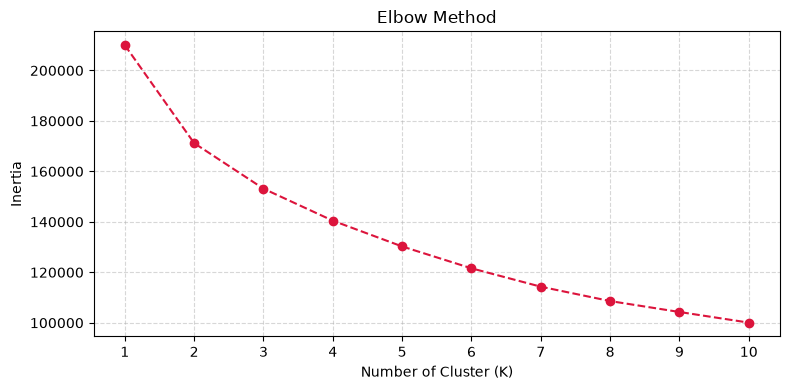

In [12]:
#Select behavioural features for clustering
cluster_cols = [
    "aggression_score",
    "anxiety_separation",
    "energy_level",
    'reactivity_to_dogs',
    'training_level'
    ]

X_cluster = df[cluster_cols].dropna()

#Standardize the dataset
scaler = StandardScaler()
X_cluster_scaled = scaler.fit_transform(X_cluster)

#Apply the Elbow Method to choose the correct cluster number (K)
inertia = []
K_range = range(1,11)

for k in K_range:
    kmeans = KMeans(n_clusters = k,
                    random_state = 42, n_init = 10)
    kmeans.fit(X_cluster_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8,4))
plt.plot(K_range, inertia, marker = 'o',
         linestyle = '--', color = 'crimson')
plt.title("Elbow Method")
plt.xlabel("Number of Cluster (K)")
plt.ylabel("Inertia")
plt.xticks(K_range)
plt.grid(True, linestyle= '--', alpha = 0.5)
plt.tight_layout()
plt.show()

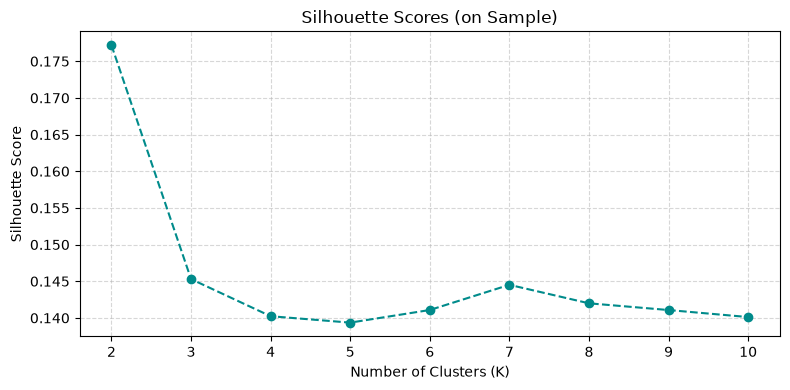

In [13]:
#Calculate the silhouette score to identify the optimal number of clusters (K) on a sample of 5000 rows
df_sample = df[cluster_cols].dropna().sample(n=5000, random_state=42)

scaler = StandardScaler()
X_sample_scaled = scaler.fit_transform(df_sample)

silhouette_scores = []
K_range = range(2, 11)

for k in K_range:
  kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
  cluster_labels = kmeans.fit_predict(X_sample_scaled)
  score = silhouette_score(X_sample_scaled, cluster_labels)
  silhouette_scores.append(score)

plt.figure(figsize=(8, 4))
plt.plot(
    range(2, 11),
    silhouette_scores,
    marker="o",
    linestyle="--",
    color="darkcyan",
)
plt.title("Silhouette Scores (on Sample)")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 11))
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


In [14]:
#Apply K-Means Clustering with K = 3
kmeans = KMeans(n_clusters = 3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_cluster_scaled)

#Add clusters labels to the original dataset
df['cluster'] = clusters
df['cluster'].value_counts().sort_index()


cluster
0    14192
1    14599
2    13209
Name: count, dtype: int64

In [15]:
#Create the dummy variables for cluster membership
df_regression = pd.get_dummies(df, columns =['cluster'], drop_first=True, dtype = int)

#Select X and y
cluster_dummy_cols= [c for c in df_regression.columns if c.startswith("cluster_")]
X_vars= ['expectation_score'] + cluster_dummy_cols

df_regression = df_regression.dropna(subset=["returned"] + X_vars)

X= df_regression[X_vars]
y= df_regression["returned"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

#Initialize the model
log_reg = LogisticRegression()
log_reg.fit(X_scaled,y)

#Display the logistic regression coefficients 
for feature, coef in zip(X.columns, log_reg.coef_[0]):
    print(f"{feature}: {coef:.4f}")

expectation_score: 0.3165
cluster_1: 0.6112
cluster_2: 0.0502


In [16]:
#Evaluate the influence of individual behavioural features on adoption return
feature_cols = cluster_cols

#Prepare the data
df_features = df.dropna(subset=['returned'] + feature_cols)
X_single = df_features[feature_cols]
y_single = df_features["returned"]

scaler = StandardScaler()
X_single_scaled = scaler.fit_transform(X_single)

#Initialize the model
log_reg_single = LogisticRegression()
log_reg_single.fit(X_single_scaled, y_single)

#Display coefficients sorted by importance
coefficients = sorted(
    zip(feature_cols,log_reg_single.coef_[0]), key=lambda x: x[1], reverse=True
)

for feature, coef in coefficients:
    print(f"{feature}: {coef:.4f}")

aggression_score: 0.5118
anxiety_separation: 0.2828
reactivity_to_dogs: 0.2106
energy_level: 0.0594
training_level: -0.2986


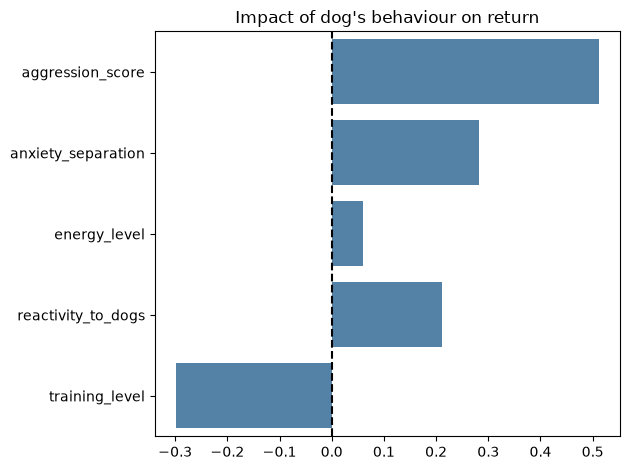

In [17]:
#Plot the coefficients
sns.barplot(x=log_reg_single.coef_[0], y= feature_cols, color= "steelblue")
plt.axvline(0, color = "black", linestyle = "--")
plt.title("Impact of dog's behaviour on return")
plt.tight_layout()
plt.show()

# Key Findings
Three behavioural clusters were identified using K-Means clustering.

Cluster membership showed an association with adoption returns, while aggression score emerged as the behavioural variable with the strongest positive influence on the probability of return.

# Predictive Modeling
The objective of this section is to compare different predictive models to identify the factors most strongly associated with dog adoption return.

## Model 1 - Dog Features vs Adopter Features

In [18]:
#Convert categorical dog features into binary dummy variables ('medical_needs', 'size', 'breed_group', 'intake_type')
df_dog_encoded = pd.get_dummies(df, columns = ["medical_needs", "size", "breed_group", "intake_type"], dtype = int)

In [19]:
#Define the features (X) and the target variable (y)
X_dog = df_dog_encoded[[
    'age_years',
    'weight_kg',
    'days_in_shelter',
    'previously_returned',
    'neutered',
    'aggression_score',
    'anxiety_separation',
    'reactivity_to_dogs',
    'energy_level',
    'training_level',
    'house_trained'
    ]
].join(
    df_dog_encoded.filter(
        regex="^(medical_needs_|size_|breed_group_|intake_type_)", axis =1
    )
).drop(columns=['size_home_mismatch'], errors='ignore')
y_dog = df_dog_encoded['returned']

In [20]:
#Split the dataset into train, validation and test set
X_dog_train_temp, X_dog_test, y_dog_train_temp, y_dog_test = train_test_split(X_dog, y_dog, test_size = 0.2, random_state = 42)

X_dog_train, X_dog_val, y_dog_train, y_dog_val = train_test_split(X_dog_train_temp, y_dog_train_temp, test_size = 0.2, random_state = 42)

In [21]:
#Initialize the model
model_dog = RandomForestClassifier(class_weight = 'balanced', random_state = 42, n_estimators=100)

#Train the model
model_dog.fit(X_dog_train, y_dog_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.

In [22]:
#Evaluate the model on the validation set
y_dog_pred = model_dog.predict(X_dog_val)

y_dog_prob = model_dog.predict_proba(X_dog_val)[:, 1]
roc_auc_dog = roc_auc_score(y_dog_val, y_dog_prob)

print("\n------Dog model------")
print("ROC_AUC Score:", roc_auc_dog)
print("Accuracy:", accuracy_score(y_dog_val, y_dog_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_dog_val, y_dog_pred))
print("\nClassification Report:\n", classification_report(y_dog_val, y_dog_pred))



------Dog model------
ROC_AUC Score: 0.7001306865744504
Accuracy: 0.8395833333333333

Confusion Matrix:
 [[5462  239]
 [ 839  180]]

Classification Report:
               precision    recall  f1-score   support

           0       0.87      0.96      0.91      5701
           1       0.43      0.18      0.25      1019

    accuracy                           0.84      6720
   macro avg       0.65      0.57      0.58      6720
weighted avg       0.80      0.84      0.81      6720



In [ ]:
#Convert categorical column 'home_type' into binary dummy variable
df_adop_encoded = pd.get_dummies(df, columns = ["home_type"], dtype = int)

In [24]:
#Define the features (X) and the target variable(y)
X_adop = df_adop_encoded[[
    'first_time_owner',
    'household_has_kids',
    'household_has_pets',
    'has_yard',
    'hours_alone_per_day',
    'adopter_activity_level'
    ]
].join(
    df_adop_encoded.filter(
        regex="^home_type_", axis =1
    )
)
y_adop = df_adop_encoded['returned']

In [25]:
#Split the dataset into train, validation and test set
X_adop_train_temp, X_adop_test, y_adop_train_temp, y_adop_test = train_test_split(X_adop, y_adop, test_size = 0.2, random_state = 42)

X_adop_train, X_adop_val, y_adop_train, y_adop_val = train_test_split(X_adop_train_temp, y_adop_train_temp, test_size = 0.2, random_state = 42)

In [26]:
#Initialize the model
model_adop = RandomForestClassifier(class_weight = 'balanced', random_state = 42, n_estimators=100)

#Train the model
model_adop.fit(X_adop_train, y_adop_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.

In [27]:
#Evaluate the model on the validation set
y_adop_pred = model_adop.predict(X_adop_val)

y_adop_prob = model_adop.predict_proba(X_adop_val)[:, 1]
roc_auc_adop = roc_auc_score(y_adop_val, y_adop_prob)

print("\n------Adopter model------")
print("ROC_AUC Score:", roc_auc_adop)
print("Accuracy:", accuracy_score(y_adop_val, y_adop_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_adop_val, y_adop_pred))
print("\nClassification Report:\n", classification_report(y_adop_val, y_adop_pred))



------Adopter model------
ROC_AUC Score: 0.5124700502761167
Accuracy: 0.727827380952381

Confusion Matrix:
 [[4720  981]
 [ 848  171]]

Classification Report:
               precision    recall  f1-score   support

           0       0.85      0.83      0.84      5701
           1       0.15      0.17      0.16      1019

    accuracy                           0.73      6720
   macro avg       0.50      0.50      0.50      6720
weighted avg       0.74      0.73      0.73      6720



In [28]:
#The dog model showed better predictive ability, so we evaluate it on the unseen test set for final performance
# Evaluate the best-performing model on the independent test set
y_dog_test_pred = model_dog.predict(X_dog_test)

y_dog_test_prob = model_dog.predict_proba(X_dog_test)[:, 1]
roc_auc_dog_test = roc_auc_score(y_dog_test, y_dog_test_prob)

print("\n------Dog model on Test set------")
print("ROC_AUC Score:", roc_auc_dog_test)
print("Accuracy:", accuracy_score(y_dog_test, y_dog_test_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_dog_test, y_dog_test_pred))
print("\nClassification Report:\n", classification_report(y_dog_test, y_dog_test_pred))



------Dog model on Test set------
ROC_AUC Score: 0.6972654258611028
Accuracy: 0.8296428571428571

Confusion Matrix:
 [[6770  347]
 [1084  199]]

Classification Report:
               precision    recall  f1-score   support

           0       0.86      0.95      0.90      7117
           1       0.36      0.16      0.22      1283

    accuracy                           0.83      8400
   macro avg       0.61      0.55      0.56      8400
weighted avg       0.79      0.83      0.80      8400



## Model 2 - Adoption Interventions

In [29]:
#Select the features (X) and the target variable (y)
X_interv = df[['visits_before_adoption', 'met_resident_pets', 'adoption_counseling']]
y_interv = df['returned']

In [30]:
#Split the dataset into train, validation and test set
X_interv_train_temp, X_interv_test, y_interv_train_temp, y_interv_test = train_test_split(X_interv, y_interv, test_size = 0.2, random_state = 42)

X_interv_train, X_interv_val, y_interv_train, y_interv_val = train_test_split(X_interv_train_temp, y_interv_train_temp, test_size = 0.2, random_state = 42)

In [31]:
#Initialize the model
model_interv = RandomForestClassifier(class_weight = 'balanced', random_state = 42, n_estimators=100)

#Train the model
model_interv.fit(X_interv_train, y_interv_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.

In [32]:
#Evaluate the model on the validation set
y_interv_pred = model_interv.predict(X_interv_val)

y_interv_prob = model_interv.predict_proba(X_interv_val)[:, 1]
roc_auc_interv = roc_auc_score(y_interv_val, y_interv_prob)

print("\n------Intervention model------")
print("ROC_AUC Score:", roc_auc_interv)
print("Accuracy:", accuracy_score(y_interv_val, y_interv_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_interv_val, y_interv_pred))
print("\nClassification Report:\n", classification_report(y_interv_val, y_interv_pred))



------Intervention model------
ROC_AUC Score: 0.5633338434332836
Accuracy: 0.5001488095238096

Confusion Matrix:
 [[2743 2958]
 [ 401  618]]

Classification Report:
               precision    recall  f1-score   support

           0       0.87      0.48      0.62      5701
           1       0.17      0.61      0.27      1019

    accuracy                           0.50      6720
   macro avg       0.52      0.54      0.44      6720
weighted avg       0.77      0.50      0.57      6720



In [33]:
feature_importances_interv= pd.DataFrame({
    'Feature': X_interv.columns,
    'Importance': model_interv.feature_importances_
}).sort_values(by='Importance', ascending=False)

print(feature_importances_interv)

                  Feature  Importance
0  visits_before_adoption    0.575653
2     adoption_counseling    0.350476
1       met_resident_pets    0.073871


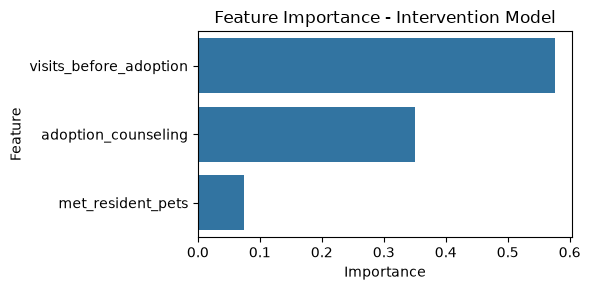

In [34]:
#Plot feature importance
plt.figure(figsize=(6, 3))

sns.barplot(
    data = feature_importances_interv,
    x = "Importance",
    y = "Feature"
)

plt.title("Feature Importance - Intervention Model")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

# Survival Analysis
This section compares the time until return for behavioural and life-circumstance related returns using Kaplan-Meier survival curves.

## Behavioural vs Life-Circumstances Returns

In [35]:
#Define the list of 'return_reason' category for two groups
behavioural_reasons = [
    'aggression',
    'conflict_with_resident_pets',
    'separation_anxiety_destruction',
    'unmet_expectations'
]

life_circumstance_reasons= [
    'housing_landlord',
    'cost_time',
    'allergies',
    'medical_needs',
    'other'
]

#Create the masks on dataframe
group_1_mask = df['return_reason'].isin(behavioural_reasons)
group_2_mask = df['return_reason'].isin(life_circumstance_reasons)

#Extract return times and events for the groups
T1 = df.loc[group_1_mask, 'days_to_return']
E1= df.loc[group_1_mask, 'returned']

T2 = df.loc[group_2_mask, 'days_to_return']
E2 = df.loc[group_2_mask, 'returned']


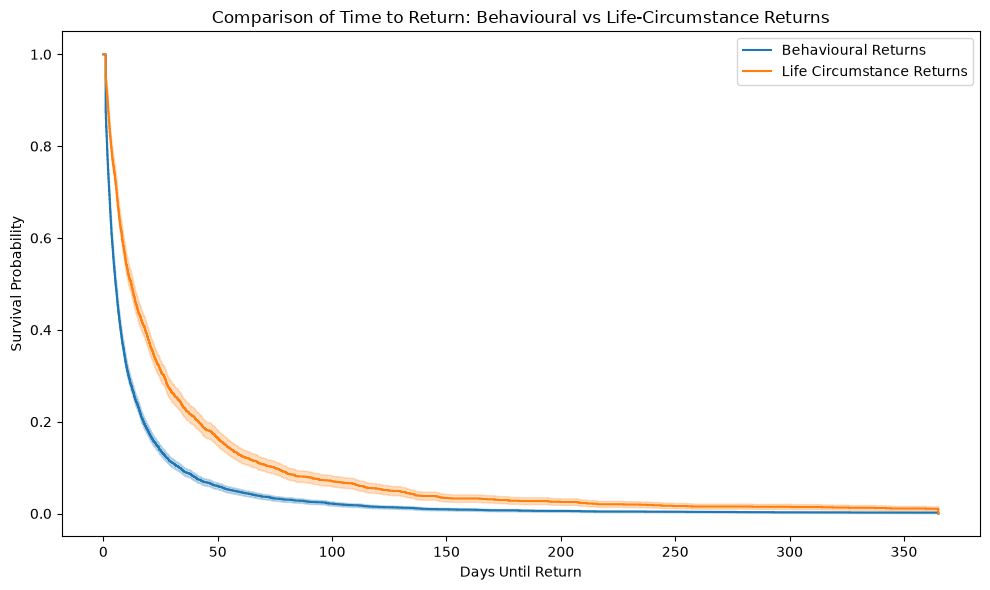

In [36]:
#Initialize the fitter for the curves
kmf1 = KaplanMeierFitter(label="Behavioural Returns")
kmf2 = KaplanMeierFitter(label = "Life Circumstance Returns")

#Fit of the data
kmf1.fit(T1, event_observed = E1)
kmf2.fit(T2, event_observed = E2)

#Plot curves on the same graphic
fig, ax = plt.subplots(figsize=(10,6))
kmf1.plot_survival_function(ax=ax)
kmf2.plot_survival_function(ax=ax)

plt.title("Comparison of Time to Return: Behavioural vs Life-Circumstance Returns")
plt.xlabel("Days Until Return")
plt.ylabel("Survival Probability")
plt.tight_layout()
plt.show()

In [ ]:
#Statistical test (Log-rank test) to determine whether the survival curves differ significantly.
results = logrank_test(T1, T2, event_observed_A = E1, event_observed_B= E2)
print(f"p-value of Log-Rank test: {results.p_value}")
if results.p_value < 0.05:
    print("The survival curves differ significantly.")
else:
    print("No statistically significant difference was detected between the survival curves.")

p-value of Log-Rank test: 2.2949578060467764e-73
The survival curves differ significantly.


# Match Score Prediction
This model combines dog, adopter and adoption-related features to estimate the probability of a successful adoption and derive a match score.

In [38]:
df_complete_encoded = pd.get_dummies(
    df, 
    columns = [
        "medical_needs", 
        "size",
        "breed_group",
        "intake_type",
        "home_type"
    ],
    dtype=int
)

In [39]:
#Define the features (X) and the target variable (y)
columns_to_drop = [
    'returned',
    'adoption_id',
    'return_reason',
    'days_to_return',
    'cluster'
    ]

X_complete = df_complete_encoded.drop(columns= columns_to_drop)
y_complete = df_complete_encoded['returned']

In [40]:
#Split the dataset into train, validation and test set
X_complete_train_temp, X_complete_test, y_complete_train_temp, y_complete_test = train_test_split(X_complete, y_complete, test_size = 0.2, random_state = 42)

X_complete_train, X_complete_val, y_complete_train, y_complete_val = train_test_split(X_complete_train_temp, y_complete_train_temp, test_size = 0.2, random_state = 42)

#Initialize the model
model_complete = RandomForestClassifier(class_weight = 'balanced', random_state = 42, n_estimators=100)

#Train the model
model_complete.fit(X_complete_train, y_complete_train)

#Evaluate the model on the validation set
y_complete_pred = model_complete.predict(X_complete_val)

y_complete_prob = model_complete.predict_proba(X_complete_val)[:, 1]
roc_auc_complete = roc_auc_score(y_complete_val, y_complete_prob)

print("\n------Complete model------")
print("ROC_AUC Score:", roc_auc_complete)
print("Accuracy:", accuracy_score(y_complete_val, y_complete_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_complete_val, y_complete_pred))
print("\nClassification Report:\n", classification_report(y_complete_val, y_complete_pred))




------Complete model------
ROC_AUC Score: 0.7316796512637712
Accuracy: 0.8455357142857143

Confusion Matrix:
 [[5515  186]
 [ 852  167]]

Classification Report:
               precision    recall  f1-score   support

           0       0.87      0.97      0.91      5701
           1       0.47      0.16      0.24      1019

    accuracy                           0.85      6720
   macro avg       0.67      0.57      0.58      6720
weighted avg       0.81      0.85      0.81      6720



In [41]:
#Calculate the match score
y_complete_prob = model_complete.predict_proba(X_complete_val)[:, 1]

match_scores = (1 - y_complete_prob) * 100
print("First 10 Match Scores")
print(match_scores[:10])

First 10 Match Scores
[92. 87. 84. 71. 91. 81. 77. 83. 54. 79.]


In [42]:
#Calculate feature importances
feature_importances_complete = pd.DataFrame({
    "Feature": X_complete.columns,
    "Importance": model_complete.feature_importances_
}).sort_values(
    by = "Importance",
    ascending=False
)

# Merge dummy variables belonging to the same original feature
feature_importances_complete["Feature"] = (
    feature_importances_complete["Feature"]
    .str.replace(r"^size_.*", "size", regex=True)
    .str.replace(r"^breed_group_.*", "breed_group", regex=True)
    .str.replace(r"^medical_needs_.*", "medical_needs", regex=True)
    .str.replace(r"^intake_type_.*", "intake_type", regex=True)
    .str.replace(r"^home_type_.*", "home_type", regex=True)
)

feature_importances_complete = (
    feature_importances_complete
    .groupby("Feature", as_index=False)["Importance"]
    .sum()
    .sort_values("Importance", ascending=False)
)

print(feature_importances_complete.head(10))

                Feature  Importance
3      aggression_score    0.107858
4    anxiety_separation    0.074844
24       training_level    0.073454
22   reactivity_to_dogs    0.066637
9     expectation_score    0.065458
8       energy_mismatch    0.058242
13  hours_alone_per_day    0.056613
26            weight_kg    0.054832
2             age_years    0.054458
6       days_in_shelter    0.052644


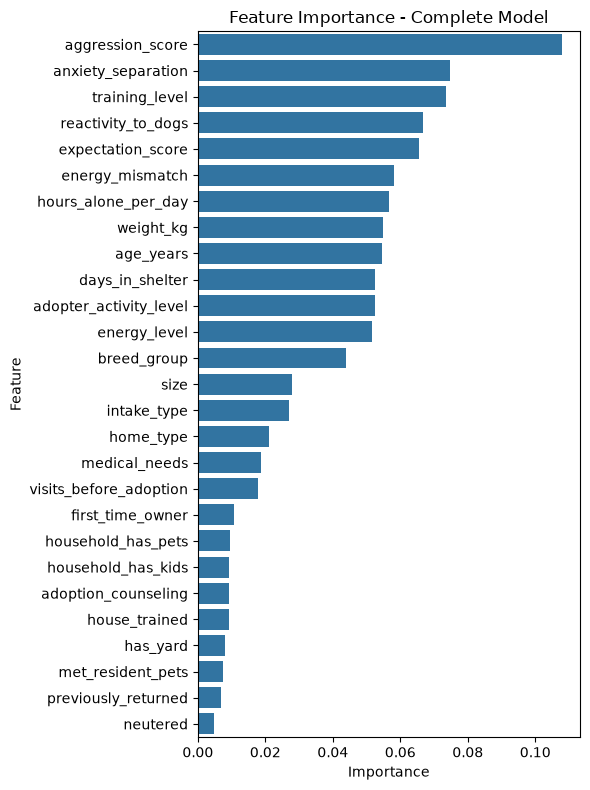

In [43]:
#Plot feature importance
plt.figure(figsize=(6, 8))

sns.barplot(
    data = feature_importances_complete,
    x = "Importance",
    y = "Feature"
)

plt.title("Feature Importance - Complete Model")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

# Conclusions
The analyses showed that behavioural characteristics of dogs were stronger predictors of adoption returns than adopter-related features alone.

Behavioural clustering identified distinct dog profiles associated with different risks, while survival analysis confirmed that behavioural returns generally occurred earlier than life-circumstances returns.

Finally, the complete Random Forest model was used to derive a Match Score that can support shelters in identifying high-risk adoptions before placement.